<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week2/lesson5/Lesson5_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 5 — Linear Systems and Least Squares: Fitting Models to Neural Data

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 2 — Linear Algebra II\
**Lesson:** Lesson 5\
**Notebook type:** Teaching notebook

> *"Lesson 4 ran a matrix forwards: known weights in, outputs out. Science usually runs it backwards: we measure the outputs and want the weights."*

---

### From computing outputs to finding inputs

In Lesson 4 the matrix and the input were known, and we computed $\mathbf{A}\mathbf{x}$. Experiments give us the other end. We record responses $\mathbf{b}$, we know the stimuli that produced them, and we want the unknown weights $\mathbf{x}$. That is the equation

$$\mathbf{A}\mathbf{x} = \mathbf{b},$$

solved for $\mathbf{x}$.

This lesson covers when that equation has exactly one solution, none, or infinitely many; how to solve it reliably; and what to do in the usual case, with more noisy measurements than unknowns, where **no** $\mathbf{x}$ fits exactly. The answer to that last case is **least squares**. It is how regression lines, encoding models, decoders and the last layer of many machine-learning models are fitted. The lesson ends by fitting a decoder to real motor-cortex data and comparing it with the population vector of Lessons 2 and 4.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-4.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-4.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def r_squared(y, y_hat):
    # Fraction of the variance of y explained by y_hat (one value per column if y is 2-D).
    y, y_hat = np.asarray(y, float), np.asarray(y_hat, float)
    return 1 - ((y - y_hat)**2).sum(axis=0) / ((y - y.mean(axis=0))**2).sum(axis=0)

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: what are this neuron's weights?**

A neuron receives two inputs with unknown synaptic weights $w_1$ and $w_2$. Its response is the weighted sum of the inputs (Lesson 2). We run two experiments:

| experiment | input 1 (spikes/s) | input 2 (spikes/s) | measured response (spikes/s) |
|---|---|---|---|
| 1 | 3 | 1 | 7 |
| 2 | 1 | 2 | 4 |

Each experiment gives one equation: $3w_1 + w_2 = 7$ and $w_1 + 2w_2 = 4$. In matrix form, with one experiment per row (Lesson 3),

$$\underbrace{\begin{pmatrix}3 & 1\\ 1 & 2\end{pmatrix}}_{\mathbf{A}}\underbrace{\begin{pmatrix}w_1\\ w_2\end{pmatrix}}_{\mathbf{x}} = \underbrace{\begin{pmatrix}7\\ 4\end{pmatrix}}_{\mathbf{b}}.$$

Two equations, two unknowns: we can solve it exactly. But real experiments are noisy, so we would run 50 trials, not 2. That gives 50 equations in 2 unknowns, and no pair of weights satisfies all 50 exactly. Then the question becomes: **which weights fit best?**

In [3]:
A_mot = np.array([[3.0, 1.0],
                  [1.0, 2.0]])      # shape (2, 2): (experiment, input), spikes/s
b_mot = np.array([7.0, 4.0])        # shape (2,): measured responses, spikes/s
w_mot = np.linalg.solve(A_mot, b_mot)
print("Weights w =", w_mot, "   check A w =", A_mot @ w_mot)

# Fifty noisy trials of the same neuron (true weights 2 and 1)
inputs_50 = RNG.uniform(0, 5, size=(50, 2))                              # shape (50, 2): (trial, input), spikes/s
responses_50 = inputs_50 @ np.array([2.0, 1.0]) + RNG.normal(0, 1.0, 50)  # shape (50,): spikes/s
try:
    np.linalg.solve(inputs_50, responses_50)
except np.linalg.LinAlgError as err:
    print("\nnp.linalg.solve with 50 equations and 2 unknowns:", err)
w_ls = np.linalg.lstsq(inputs_50, responses_50, rcond=None)[0]
print("Least-squares weights from 50 noisy trials:", np.round(w_ls, 3), " (true: [2, 1])")

Weights w = [2. 1.]    check A w = [7. 4.]

np.linalg.solve with 50 equations and 2 unknowns: Last 2 dimensions of the array must be square
Least-squares weights from 50 noisy trials: [2.018 0.946]  (true: [2, 1])


# **Part 1: Linear Systems — Two Pictures**

A system of linear equations $\mathbf{A}\mathbf{x} = \mathbf{b}$ can be pictured in two ways.

**Row picture.** Each equation (row) is a line in the plane of unknowns $(w_1, w_2)$; in three unknowns it is a plane. A solution must lie on every line at once, so it is their **intersection**.

**Column picture.** By the column view of Lesson 4, $\mathbf{A}\mathbf{x} = w_1\mathbf{a}_{:,1} + w_2\mathbf{a}_{:,2}$. Solving means finding the amounts $w_1, w_2$ of the two columns that **add up to** $\mathbf{b}$.

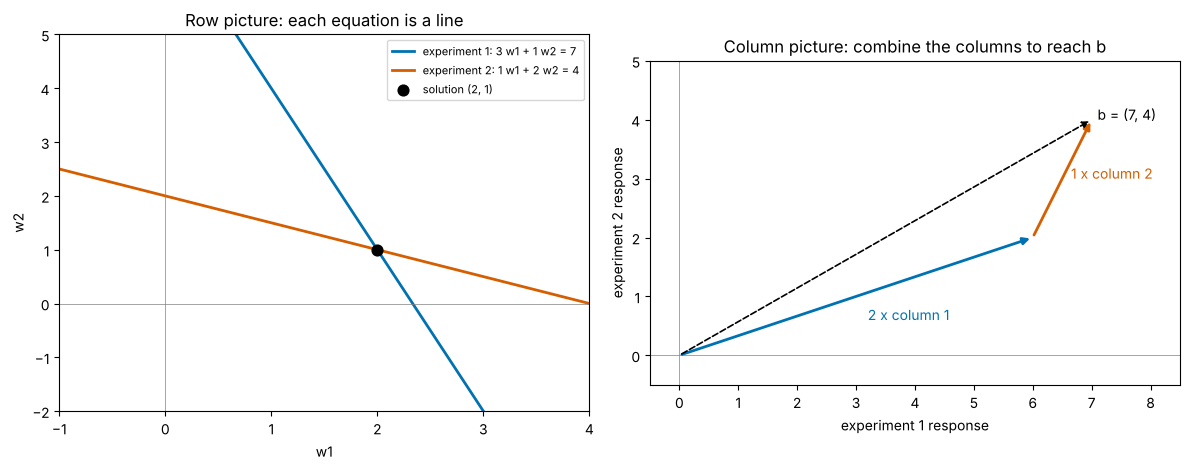

In [4]:
w1_grid = np.linspace(-1, 4, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for i, colour in zip(range(2), PALETTE):
    a1, a2 = A_mot[i]
    ax.plot(w1_grid, (b_mot[i] - a1 * w1_grid) / a2, color=colour, lw=2, label=f'experiment {i + 1}: {a1:g} w1 + {a2:g} w2 = {b_mot[i]:g}')
ax.scatter(*w_mot, color='black', s=60, zorder=3, label=f'solution ({w_mot[0]:g}, {w_mot[1]:g})')
ax.set_xlim(-1, 4); ax.set_ylim(-2, 5); ax.set_xlabel('w1'); ax.set_ylabel('w2')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_title('Row picture: each equation is a line'); ax.legend(fontsize=8)

ax = axes[1]
c1, c2 = A_mot[:, 0], A_mot[:, 1]
ax.annotate('', xy=w_mot[0] * c1, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=PALETTE[0], lw=2))
ax.annotate('', xy=w_mot[0] * c1 + w_mot[1] * c2, xytext=w_mot[0] * c1, arrowprops=dict(arrowstyle='-|>', color=PALETTE[1], lw=2))
ax.annotate('', xy=b_mot, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2, ls='--'))
ax.text(*(w_mot[0] * c1 / 2 + [0.2, -0.4]), f'{w_mot[0]:g} x column 1', color=PALETTE[0])
ax.text(*(w_mot[0] * c1 + w_mot[1] * c2 / 2 + [0.15, 0]), f'{w_mot[1]:g} x column 2', color=PALETTE[1])
ax.text(b_mot[0] + 0.1, b_mot[1], 'b = (7, 4)')
ax.set_xlim(-0.5, 8.5); ax.set_ylim(-0.5, 5); ax.set_aspect('equal')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel('experiment 1 response'); ax.set_ylabel('experiment 2 response')
ax.set_title('Column picture: combine the columns to reach b')
plt.tight_layout()
plt.show()

### One solution, none, or infinitely many

Two lines in a plane meet once, never (parallel), or everywhere (the same line). Lesson 4 gives the test: a square $\mathbf{A}$ has exactly one solution for every $\mathbf{b}$ when $\det\mathbf{A} \neq 0$, that is, when its columns point in independent directions (full rank). When $\det\mathbf{A} = 0$, whether there are no solutions or infinitely many depends on $\mathbf{b}$.

In the experiment: if experiment 2 used inputs exactly twice those of experiment 1, it would add no new information about the weights, and the two equations would either contradict each other or repeat each other.

In [5]:
cases = {
    'independent experiments': (np.array([[3.0, 1.0], [1.0, 2.0]]), np.array([7.0, 4.0])),
    'parallel, contradictory': (np.array([[3.0, 1.0], [6.0, 2.0]]), np.array([7.0, 10.0])),
    'same line twice': (np.array([[3.0, 1.0], [6.0, 2.0]]), np.array([7.0, 14.0])),
}
for name, (A_c, b_c) in cases.items():
    rank_A = np.linalg.matrix_rank(A_c)
    rank_Ab = np.linalg.matrix_rank(np.column_stack([A_c, b_c]))
    verdict = 'one solution' if rank_A == 2 else ('no solution' if rank_Ab > rank_A else 'infinitely many')
    print(f"{name:<26} det = {np.linalg.det(A_c):5.1f}   rank A = {rank_A}   rank [A | b] = {rank_Ab}   -> {verdict}")

independent experiments    det =   5.0   rank A = 2   rank [A | b] = 2   -> one solution
parallel, contradictory    det =   0.0   rank A = 1   rank [A | b] = 2   -> no solution
same line twice            det =   0.0   rank A = 1   rank [A | b] = 1   -> infinitely many


The rank test in the last column works for any system, square or not: there is a solution exactly when appending $\mathbf{b}$ as an extra column does not raise the rank, which means $\mathbf{b}$ is already a combination of the columns of $\mathbf{A}$. It is unique when, in addition, the rank equals the number of unknowns.

#### Animation: turning experiment 2 until the lines are parallel

In [6]:
# INTERACTIVE ANIMATION -- experiment 2's input 1 goes from 0 to 8 (input 2 fixed at 2); at 6 the lines are parallel
a21_values = np.round(np.linspace(0, 8, 33), 2)
w1_line = np.linspace(-6, 8, 2)
fig_rows = go.Figure([
    go.Scatter(x=w1_line, y=7 - 3 * w1_line, mode='lines', name='3 w1 + 1 w2 = 7', line=dict(color=PALETTE[0], width=3)),
    go.Scatter(x=w1_line, y=(4 - a21_values[0] * w1_line) / 2, mode='lines', name='experiment 2', line=dict(color=PALETTE[1], width=3)),
    go.Scatter(x=[np.linalg.solve([[3, 1], [a21_values[0], 2]], [7, 4])[0]], y=[np.linalg.solve([[3, 1], [a21_values[0], 2]], [7, 4])[1]],
               mode='markers', name='solution', marker=dict(color='black', size=12)),
])
frames = []
for k, a21 in enumerate(a21_values):
    M = np.array([[3.0, 1.0], [a21, 2.0]])
    det = np.linalg.det(M)
    if abs(det) > 1e-9:
        sol = np.linalg.solve(M, [7.0, 4.0]); pt = dict(x=[sol[0]], y=[sol[1]]); note = f'solution ({sol[0]:.2f}, {sol[1]:.2f})'
    else:
        pt = dict(x=[None], y=[None]); note = 'parallel lines: no solution'
    frames.append(go.Frame(name=str(k), data=[go.Scatter(x=w1_line, y=7 - 3 * w1_line), go.Scatter(x=w1_line, y=(4 - a21 * w1_line) / 2), go.Scatter(**pt)],
                           layout=go.Layout(title=f'experiment 2: {a21:g} w1 + 2 w2 = 4    det = {det:+.2f}    {note}')))
fig_rows.frames = frames
buttons, sliders = play_pause_and_slider([f'{a:g}' for a in a21_values], prefix='experiment 2, input 1 = ')
fig_rows.update_layout(title=frames[0].layout.title.text, xaxis=dict(range=[-6, 8], title='w1'), yaxis=dict(range=[-6, 8], title='w2'),
                       template='plotly_white', width=720, height=600, updatemenus=buttons, sliders=sliders)
fig_rows.show(config=PLOTLY_CONFIG)

Watch the solution as the lines approach parallel ($a_{21}$ near 6): it races off towards infinity. When two experiments are **nearly** redundant, a tiny change in the data moves the answer enormously. Part 2 makes that precise.

# **Part 2: Solving — Elimination, and Why `solve` Beats `inv`**

### Elimination by hand

**Gaussian elimination** solves a system by subtracting multiples of one equation from another until the system is triangular, then reading off the unknowns from the bottom up (**back substitution**). Subtracting a multiple of one equation from another never changes the solutions. For

$$\begin{aligned}2x_1 + x_2 + x_3 &= 4\\ 4x_1 + 3x_2 + 3x_3 &= 10\\ 8x_1 + 7x_2 + 9x_3 &= 24\end{aligned}$$

subtract 2 × row 1 from row 2 and 4 × row 1 from row 3, then 3 × the new row 2 from row 3:

$$\begin{aligned}2x_1 + x_2 + x_3 &= 4\\ x_2 + x_3 &= 2\\ 2x_3 &= 2\end{aligned}$$

so $x_3 = 1$, then $x_2 = 2 - 1 = 1$, then $x_1 = (4 - 1 - 1)/2 = 1$. The code below does exactly this, with one refinement: before each step it swaps in the row with the largest pivot (**partial pivoting**), which keeps rounding errors small.

In [7]:
def gaussian_elimination(A, b):
    # Solve the square system A x = b by elimination with partial pivoting, then back substitution.
    M = np.column_stack([np.asarray(A, float), np.asarray(b, float)])   # augmented matrix [A | b]
    n = M.shape[0]
    for col in range(n):
        pivot = col + np.argmax(np.abs(M[col:, col]))                   # row with the largest entry in this column
        M[[col, pivot]] = M[[pivot, col]]                                # swap it into place
        for row in range(col + 1, n):
            M[row] -= (M[row, col] / M[col, col]) * M[col]             # eliminate below the pivot
    x = np.zeros(n)
    for row in range(n - 1, -1, -1):                                     # back substitution
        x[row] = (M[row, -1] - M[row, row + 1:n] @ x[row + 1:]) / M[row, row]
    return x

A3 = np.array([[2.0, 1.0, 1.0], [4.0, 3.0, 3.0], [8.0, 7.0, 9.0]])
b3 = np.array([4.0, 10.0, 24.0])
print("Our elimination :", gaussian_elimination(A3, b3))
print("np.linalg.solve :", np.linalg.solve(A3, b3))

Our elimination : [1. 1. 1.]
np.linalg.solve : [1. 1. 1.]


### Solve, don't invert

It is tempting to compute $\mathbf{A}^{-1}$ and then $\mathbf{x} = \mathbf{A}^{-1}\mathbf{b}$. **Don't.** `np.linalg.solve` performs elimination directly. It is faster than forming the inverse, because it skips work that is not needed (the timing below shows the gap), and it is usually more accurate. Forming an inverse is only worth it if you truly need the inverse matrix itself.

The accuracy difference matters most for **ill-conditioned** matrices: those close to having no inverse, like the nearly parallel lines above. Their **condition number** $\kappa(\mathbf{A})$, from `np.linalg.cond`, measures how much relative errors can be amplified:

$$\frac{\lVert\delta\mathbf{x}\rVert}{\lVert\mathbf{x}\rVert} \le \kappa(\mathbf{A})\,\frac{\lVert\delta\mathbf{b}\rVert}{\lVert\mathbf{b}\rVert}.$$

A condition number of $10^k$ means you can lose up to $k$ digits of accuracy. Computers keep about 16 digits, so a condition number near $10^{16}$ means the answer may have no correct digits at all.

In [8]:
import time
n_big = 1500
A_big = RNG.normal(size=(n_big, n_big)); b_big = RNG.normal(size=n_big)
t0 = time.perf_counter(); x_solve = np.linalg.solve(A_big, b_big); t_solve = time.perf_counter() - t0
t0 = time.perf_counter(); x_inv = np.linalg.inv(A_big) @ b_big; t_inv = time.perf_counter() - t0
print(f"{n_big} x {n_big} system:  solve {t_solve * 1000:.0f} ms,  inv then multiply {t_inv * 1000:.0f} ms")

# An ill-conditioned matrix: the Hilbert matrix, h_ij = 1 / (i + j - 1)
for n in [4, 8, 12]:
    H = 1.0 / (np.arange(1, n + 1)[:, None] + np.arange(1, n + 1)[None, :] - 1)
    x_true = np.ones(n)
    b_H = H @ x_true
    err_solve = np.linalg.norm(np.linalg.solve(H, b_H) - x_true)
    err_inv = np.linalg.norm(np.linalg.inv(H) @ b_H - x_true)
    print(f"Hilbert n = {n:>2}: condition number {np.linalg.cond(H):.1e}   error with solve {err_solve:.1e}   with inv {err_inv:.1e}")

1500 x 1500 system:  solve 71 ms,  inv then multiply 179 ms
Hilbert n =  4: condition number 1.6e+04   error with solve 6.7e-14   with inv 2.1e-12
Hilbert n =  8: condition number 1.5e+10   error with solve 1.9e-07   with inv 1.4e-06
Hilbert n = 12: condition number 1.6e+16   error with solve 4.5e-01   with inv 9.4e+00


condition number 488
b = [ 7.  13.8]        -> w = [2. 1.]
b = [ 7.  13.9]  -> w = [1. 4.]   (a 0.7% change in b)


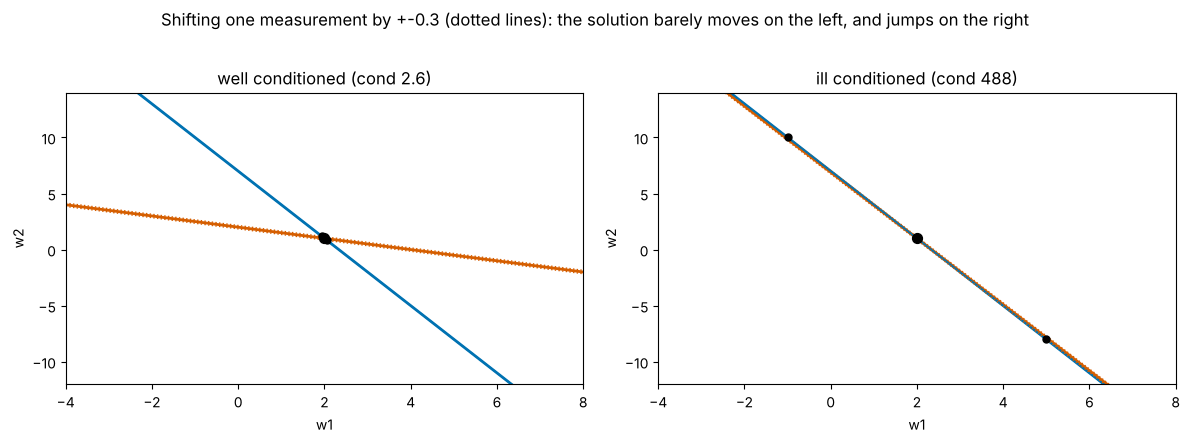

In [9]:
# Nearly redundant experiments: a tiny change in one measurement moves the answer a long way
A_ill = np.array([[3.0, 1.0], [5.9, 2.0]])      # experiment 2 is almost twice experiment 1
b_ill = np.array([7.0, 13.8])
x_ill = np.linalg.solve(A_ill, b_ill)
x_ill2 = np.linalg.solve(A_ill, b_ill + np.array([0.0, 0.1]))
print(f"condition number {np.linalg.cond(A_ill):.0f}")
print(f"b = {b_ill}        -> w = {np.round(x_ill, 2)}")
print(f"b = {b_ill + [0, 0.1]}  -> w = {np.round(x_ill2, 2)}   (a 0.7% change in b)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, (M, b_vec, title) in zip(axes, [(A_mot, b_mot, f'well conditioned (cond {np.linalg.cond(A_mot):.1f})'),
                                         (A_ill, b_ill, f'ill conditioned (cond {np.linalg.cond(A_ill):.0f})')]):
    w1 = np.linspace(-4, 8, 2)
    for shift, ls in [(0.0, '-'), (0.3, ':'), (-0.3, ':')]:
        ax.plot(w1, (b_vec[0] - M[0, 0] * w1) / M[0, 1], color=PALETTE[0], lw=2 if shift == 0 else 1)
        ax.plot(w1, (b_vec[1] + shift - M[1, 0] * w1) / M[1, 1], color=PALETTE[1], ls=ls, lw=2 if shift == 0 else 1)
        sol = np.linalg.solve(M, b_vec + [0, shift]); ax.scatter(*sol, color='black', s=25 if shift else 50, zorder=3)
    ax.set_xlim(-4, 8); ax.set_ylim(-12, 14); ax.set_xlabel('w1'); ax.set_ylabel('w2'); ax.set_title(title)
fig.suptitle('Shifting one measurement by +-0.3 (dotted lines): the solution barely moves on the left, and jumps on the right', y=1.02)
plt.tight_layout()
plt.show()

# **Part 3: Too Many Equations, or Too Few**

Real problems are rarely square.

**Overdetermined** (more equations than unknowns, a tall $\mathbf{A}$): with noisy data the equations almost always contradict each other. In the row picture, three lines in the plane with no common point. In the column picture, $\mathbf{A}\mathbf{x}$ can only reach the **column space** of $\mathbf{A}$, the set of combinations of its columns, which for a $3\times2$ matrix is a plane inside 3-D space. A noisy $\mathbf{b}$ lies off that plane, so no $\mathbf{x}$ works.

**Underdetermined** (fewer equations than unknowns, a wide $\mathbf{A}$): there are directions $\mathbf{n}$ with $\mathbf{A}\mathbf{n} = \mathbf{0}$ (Lesson 4), so if $\mathbf{x}$ is a solution then so is $\mathbf{x} + t\,\mathbf{n}$ for every $t$. There are infinitely many solutions, and the data cannot tell them apart.

In [10]:
A_over = np.array([[3.0, 1.0], [1.0, 2.0], [2.0, 2.0]])     # 3 experiments, 2 unknown weights
b_over = np.array([7.0, 4.0, 6.5])                          # noisy: no (w1, w2) satisfies all three
print("rank A =", np.linalg.matrix_rank(A_over), "  rank [A | b] =", np.linalg.matrix_rank(np.column_stack([A_over, b_over])), " -> no exact solution")

A_under = np.array([[3.0, 1.0]])                            # 1 experiment, 2 unknowns
b_under = np.array([7.0])
n_null = np.array([1.0, -3.0])                              # A_under @ n_null = 0
for t in [0.0, 0.5, 1.0]:
    x_try = np.array([2.0, 1.0]) + t * n_null
    print(f"underdetermined: w = {x_try} gives A w = {A_under @ x_try}")

rank A = 2   rank [A | b] = 3  -> no exact solution
underdetermined: w = [2. 1.] gives A w = [7.]
underdetermined: w = [ 2.5 -0.5] gives A w = [7.]
underdetermined: w = [ 3. -2.] gives A w = [7.]


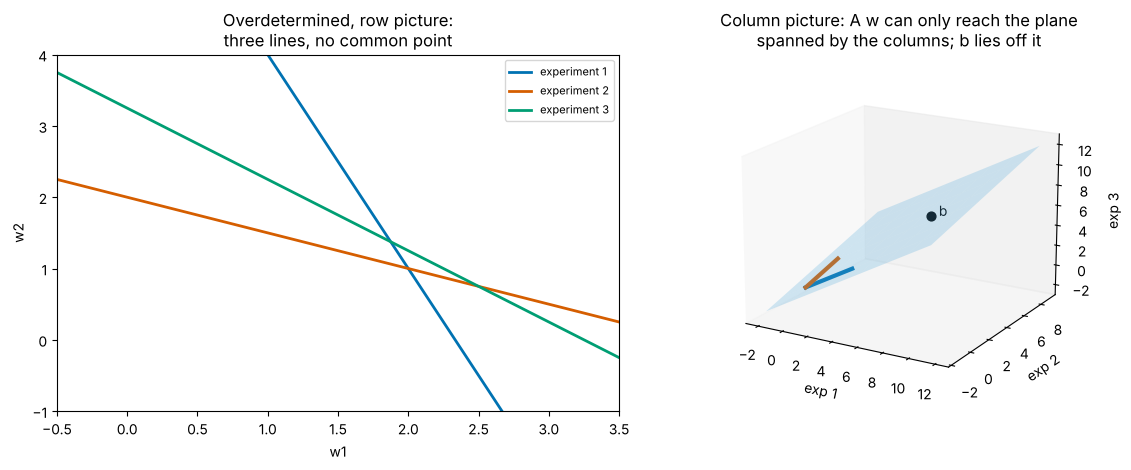

In [11]:
fig = plt.figure(figsize=(12, 4.8))
ax = fig.add_subplot(1, 2, 1)
w1 = np.linspace(-1, 4, 2)
for i, colour in zip(range(3), PALETTE):
    ax.plot(w1, (b_over[i] - A_over[i, 0] * w1) / A_over[i, 1], color=colour, lw=2, label=f'experiment {i + 1}')
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-1, 4); ax.set_xlabel('w1'); ax.set_ylabel('w2')
ax.set_title('Overdetermined, row picture:\nthree lines, no common point'); ax.legend(fontsize=8)

ax = fig.add_subplot(1, 2, 2, projection='3d')
s_grid, t_grid = np.meshgrid(np.linspace(-0.5, 3, 8), np.linspace(-0.5, 3, 8))
plane = A_over[:, :1, None] * s_grid + A_over[:, 1:, None] * t_grid
ax.plot_surface(plane[0], plane[1], plane[2], alpha=0.25, color=PALETTE[5])
ax.scatter(*b_over, color='black', s=40)
ax.text(*b_over, '  b', fontsize=10)
for col, colour in [(A_over[:, 0], PALETTE[0]), (A_over[:, 1], PALETTE[1])]:
    ax.plot([0, col[0]], [0, col[1]], [0, col[2]], color=colour, lw=3)
ax.set_xlabel('exp 1'); ax.set_ylabel('exp 2'); ax.set_zlabel('exp 3'); ax.grid(False)
ax.view_init(elev=18, azim=-60)
ax.set_title('Column picture: A w can only reach the plane\nspanned by the columns; b lies off it')
plt.tight_layout()
plt.show()

# **Part 4: Least Squares — the Best Compromise**

When no $\mathbf{x}$ solves $\mathbf{A}\mathbf{x} = \mathbf{b}$, choose the one that makes the **residual** $\mathbf{r} = \mathbf{b} - \mathbf{A}\mathbf{x}$ as short as possible. Its squared length is the **sum of squared errors**:

$$\text{SSE}(\mathbf{x}) = \lVert\mathbf{b} - \mathbf{A}\mathbf{x}\rVert^2 = \sum_{i}\big(b_i - (\mathbf{A}\mathbf{x})_i\big)^2 .$$

**Geometry gives the answer.** $\mathbf{A}\mathbf{x}$ ranges over the column space. The point of the column space closest to $\mathbf{b}$ is the **projection** of $\mathbf{b}$ onto it, and (exactly as for projection onto a line in Lesson 2) the leftover residual is **orthogonal** to the column space, that is, to every column of $\mathbf{A}$:

$$\mathbf{A}^{\mathsf T}(\mathbf{b} - \mathbf{A}\hat{\mathbf{x}}) = \mathbf{0}\quad\Longleftrightarrow\quad \mathbf{A}^{\mathsf T}\mathbf{A}\,\hat{\mathbf{x}} = \mathbf{A}^{\mathsf T}\mathbf{b}.$$

These are the **normal equations** ("normal" means perpendicular). They are a square system with one equation per unknown, and when the columns of $\mathbf{A}$ are independent they have exactly one solution, $\hat{\mathbf{x}} = (\mathbf{A}^{\mathsf T}\mathbf{A})^{-1}\mathbf{A}^{\mathsf T}\mathbf{b}$.

### Fitting a line is least squares

A neuron is shown gratings of different contrast. Model its rate as a straight line, $\text{rate} \approx \beta_0 + \beta_1\,\text{contrast}$. Each trial gives one equation $\beta_0 + \beta_1 c_i \approx r_i$, so the unknowns are $(\beta_0, \beta_1)$ and the matrix has a **column of ones** for the intercept (the augmented-matrix trick of Lesson 4):

$$\underbrace{\begin{pmatrix}1 & c_1\\ 1 & c_2\\ \vdots & \vdots\\ 1 & c_n\end{pmatrix}}_{\text{design matrix } \mathbf{X}}\begin{pmatrix}\beta_0\\ \beta_1\end{pmatrix}\approx\begin{pmatrix}r_1\\ r_2\\ \vdots\\ r_n\end{pmatrix}.$$

In [12]:
contrast = np.repeat([0.05, 0.1, 0.2, 0.3, 0.45, 0.6], 5)            # shape (30,): stimulus contrast, 0 to 1
rate = 8.0 + 30.0 * contrast + RNG.normal(0, 2.5, contrast.size)      # shape (30,): spikes/s (true intercept 8, slope 30)
X_line = np.column_stack([np.ones_like(contrast), contrast])          # shape (30, 2): design matrix (intercept, contrast)

beta_normal = np.linalg.solve(X_line.T @ X_line, X_line.T @ rate)     # normal equations
beta_lstsq = np.linalg.lstsq(X_line, rate, rcond=None)[0]              # NumPy's least-squares solver
residual = rate - X_line @ beta_lstsq

print("design matrix shape:", X_line.shape, " (trial, [intercept, contrast])")
print("normal equations: beta =", np.round(beta_normal, 3))
print("np.linalg.lstsq : beta =", np.round(beta_lstsq, 3), "  (intercept in spikes/s, slope in spikes/s per unit contrast)")
print("X^T r =", np.round(X_line.T @ residual, 10), " -> the residual is orthogonal to both columns")
print(f"R^2 = {r_squared(rate, X_line @ beta_lstsq):.3f}")

design matrix shape: (30, 2)  (trial, [intercept, contrast])
normal equations: beta = [ 8.153 29.508]
np.linalg.lstsq : beta = [ 8.153 29.508]   (intercept in spikes/s, slope in spikes/s per unit contrast)
X^T r = [0. 0.]  -> the residual is orthogonal to both columns
R^2 = 0.809


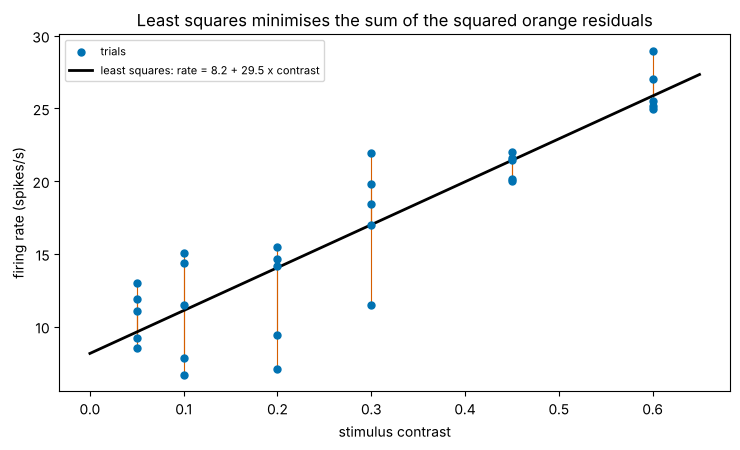

In [13]:
c_line = np.linspace(0, 0.65, 2)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
fitted = X_line @ beta_lstsq
for c_i, r_i, f_i in zip(contrast, rate, fitted):
    ax.plot([c_i, c_i], [r_i, f_i], color=PALETTE[1], lw=0.8)
ax.scatter(contrast, rate, color=PALETTE[0], s=25, zorder=3, label='trials')
ax.plot(c_line, beta_lstsq[0] + beta_lstsq[1] * c_line, color='black', lw=2,
        label=f'least squares: rate = {beta_lstsq[0]:.1f} + {beta_lstsq[1]:.1f} x contrast')
ax.set_xlabel('stimulus contrast'); ax.set_ylabel('firing rate (spikes/s)')
ax.set_title('Least squares minimises the sum of the squared orange residuals')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Interactive version: search for the best slope by hand

In [14]:
# INTERACTIVE -- for each slope, use the best intercept for that slope; the SSE curve bottoms out at the least-squares slope
slopes = np.round(np.linspace(10, 50, 41), 1)
def best_intercept(s):
    return np.mean(rate - s * contrast)
sse = np.array([np.sum((rate - best_intercept(s) - s * contrast)**2) for s in slopes])
fig_sse = make_subplots(rows=1, cols=2, subplot_titles=('Data and line', 'Sum of squared errors'))
fig_sse.add_trace(go.Scatter(x=contrast, y=rate, mode='markers', marker=dict(color=PALETTE[0]), name='trials'), row=1, col=1)
fig_sse.add_trace(go.Scatter(x=c_line, y=best_intercept(slopes[0]) + slopes[0] * c_line, mode='lines', line=dict(color='black'), name='line'), row=1, col=1)
fig_sse.add_trace(go.Scatter(x=slopes, y=sse, mode='lines', line=dict(color='lightgrey'), name='SSE'), row=1, col=2)
fig_sse.add_trace(go.Scatter(x=[slopes[0]], y=[sse[0]], mode='markers', marker=dict(color=PALETTE[1], size=12), name='current slope'), row=1, col=2)
fig_sse.add_vline(x=beta_lstsq[1], line_dash='dash', line_color=PALETTE[2], row=1, col=2)
fig_sse.frames = [go.Frame(name=str(k), traces=[1, 3], data=[go.Scatter(x=c_line, y=best_intercept(s) + s * c_line), go.Scatter(x=[s], y=[sse[k]])],
                           layout=go.Layout(title=f'slope {s:.1f} spikes/s per unit contrast:  SSE = {sse[k]:.0f}  (least squares: slope {beta_lstsq[1]:.1f}, SSE {sse.min():.0f})'))
                   for k, s in enumerate(slopes)]
buttons, sliders = play_pause_and_slider([f'{s:g}' for s in slopes], prefix='slope = ', duration=100)
fig_sse.update_xaxes(title_text='contrast', row=1, col=1); fig_sse.update_yaxes(title_text='rate (spikes/s)', row=1, col=1)
fig_sse.update_xaxes(title_text='slope', row=1, col=2); fig_sse.update_yaxes(title_text='SSE (spikes/s)^2', row=1, col=2)
fig_sse.update_layout(title=fig_sse.frames[0].layout.title.text, template='plotly_white', width=980, height=480, updatemenus=buttons, sliders=sliders, showlegend=False)
fig_sse.show(config=PLOTLY_CONFIG)

### The projection, in 3-D

For the three-experiment example of Part 3, we can draw it. The least-squares $\hat{\mathbf{x}}$ makes $\mathbf{A}\hat{\mathbf{x}}$ the foot of the perpendicular from $\mathbf{b}$ to the column-space plane. The residual is the perpendicular itself.

In [15]:
x_hat_over = np.linalg.lstsq(A_over, b_over, rcond=None)[0]
p_over = A_over @ x_hat_over
res_over = b_over - p_over
print("least-squares weights:", np.round(x_hat_over, 3))
print("projection A x_hat   :", np.round(p_over, 3), "   residual:", np.round(res_over, 3))
print("residual . column 1 =", round(res_over @ A_over[:, 0], 12), "   residual . column 2 =", round(res_over @ A_over[:, 1], 12))

fig_proj = go.Figure()
fig_proj.add_trace(go.Surface(x=plane[0], y=plane[1], z=plane[2], opacity=0.35, showscale=False, colorscale=[[0, PALETTE[5]], [1, PALETTE[5]]], name='column space'))
fig_proj.add_trace(go.Scatter3d(x=[b_over[0]], y=[b_over[1]], z=[b_over[2]], mode='markers+text', text=['b'], marker=dict(size=6, color='black'), name='b'))
fig_proj.add_trace(go.Scatter3d(x=[p_over[0]], y=[p_over[1]], z=[p_over[2]], mode='markers+text', text=['A x_hat'], marker=dict(size=6, color=PALETTE[2]), name='projection'))
fig_proj.add_trace(go.Scatter3d(x=[p_over[0], b_over[0]], y=[p_over[1], b_over[1]], z=[p_over[2], b_over[2]], mode='lines', line=dict(color=PALETTE[1], width=6), name='residual'))
fig_proj.update_layout(title='Least squares = projection of b onto the column space', template='plotly_white', width=760, height=600,
                       scene=dict(xaxis_title='experiment 1', yaxis_title='experiment 2', zaxis_title='experiment 3', aspectmode='data'))
fig_proj.show(config=PLOTLY_CONFIG)

least-squares weights: [2.    1.111]
projection A x_hat   : [7.111 4.222 6.222]    residual: [-0.111 -0.222  0.278]
residual . column 1 = 0.0    residual . column 2 = 0.0


# **Part 5: The Pseudoinverse and Numerical Stability**

### The pseudoinverse

NumPy's `np.linalg.pinv(A)` returns the **pseudoinverse** $\mathbf{A}^{+}$, a matrix that gives the least-squares answer as $\hat{\mathbf{x}} = \mathbf{A}^{+}\mathbf{b}$ for any shape of $\mathbf{A}$:
- if $\mathbf{A}$ is square and invertible, $\mathbf{A}^{+} = \mathbf{A}^{-1}$;
- if $\mathbf{A}$ is tall with independent columns, $\mathbf{A}^{+} = (\mathbf{A}^{\mathsf T}\mathbf{A})^{-1}\mathbf{A}^{\mathsf T}$, the normal-equation solution;
- if there are many least-squares solutions (underdetermined or rank-deficient), $\mathbf{A}^{+}\mathbf{b}$ is the one with the **smallest length**.

`np.linalg.lstsq` computes the same answer without forming $\mathbf{A}^{+}$, and is what you should normally use.

In [16]:
print("tall A: pinv(A) b =", np.round(np.linalg.pinv(A_over) @ b_over, 4), "  lstsq =", np.round(x_hat_over, 4))

x_min = np.linalg.pinv(A_under) @ b_under
print(f"\nunderdetermined 3 w1 + w2 = 7: pinv gives w = {np.round(x_min, 3)}, length {np.linalg.norm(x_min):.3f}")
for t in [-0.3, 0.3]:
    other = x_min + t * n_null
    print(f"  another solution {np.round(other, 3)}: A w = {A_under @ other}, length {np.linalg.norm(other):.3f}")

tall A: pinv(A) b = [2.     1.1111]   lstsq = [2.     1.1111]

underdetermined 3 w1 + w2 = 7: pinv gives w = [2.1 0.7], length 2.214
  another solution [1.8 1.6]: A w = [7.], length 2.408
  another solution [ 2.4 -0.2]: A w = [7.], length 2.408


The minimum-length solution is a **choice**: the data did not pick it. With fewer measurements than unknowns, any answer you report contains an assumption you added. Exercise 7 shows what that does to a decoder with more weights than training samples.

### Why not just use the normal equations?

The normal equations are perfect on paper and risky on a computer: forming $\mathbf{A}^{\mathsf T}\mathbf{A}$ **squares the condition number**, $\kappa(\mathbf{A}^{\mathsf T}\mathbf{A}) = \kappa(\mathbf{A})^2$. A design matrix with $\kappa = 10^8$, harmless by itself, becomes $10^{16}$, at the limit of what 16-digit arithmetic can handle. `lstsq` works with $\mathbf{A}$ directly (through a factorisation called the SVD, which Lessons 6 and 7 build towards) and avoids the squaring.

Polynomial features are a classic case: $1, c, c^2, \dots, c^{10}$ for $c$ between 0 and 1 are nearly parallel columns.

In [17]:
c_poly = np.linspace(0, 1, 40)
true_coef = RNG.normal(size=11)
for degree in [4, 7, 10]:
    V_poly = np.vander(c_poly, degree + 1, increasing=True)        # columns 1, c, c^2, ..., c^degree
    y_poly = V_poly @ true_coef[:degree + 1]                        # exact data, no noise
    coef_normal = np.linalg.solve(V_poly.T @ V_poly, V_poly.T @ y_poly)
    coef_lstsq = np.linalg.lstsq(V_poly, y_poly, rcond=None)[0]
    print(f"degree {degree:>2}: cond(X) = {np.linalg.cond(V_poly):.1e}, cond(X^T X) = {np.linalg.cond(V_poly.T @ V_poly):.1e};  "
          f"coefficient error: normal equations {np.linalg.norm(coef_normal - true_coef[:degree + 1]):.1e}, lstsq {np.linalg.norm(coef_lstsq - true_coef[:degree + 1]):.1e}")

degree  4: cond(X) = 6.3e+02, cond(X^T X) = 4.0e+05;  coefficient error: normal equations 1.4e-12, lstsq 1.8e-14
degree  7: cond(X) = 1.1e+05, cond(X^T X) = 1.2e+10;  coefficient error: normal equations 3.1e-07, lstsq 1.3e-12
degree 10: cond(X) = 2.0e+07, cond(X^T X) = 4.1e+14;  coefficient error: normal equations 4.3e-04, lstsq 7.8e-11


With exact, noise-free data, both methods should recover the true coefficients. At degree 10, `lstsq` still does so to many digits, while the normal equations have lost most of them. Same mathematics, different arithmetic.

# **Part 6: Design Matrices — Intercepts, Units and Feature Coding**

A **design matrix** $\mathbf{X}$ has one row per observation (trial, time bin) and one column per **regressor**: a quantity the model may use to explain the response $\mathbf{y}$. Fitting $\mathbf{y} \approx \mathbf{X}\boldsymbol{\beta}$ by least squares gives one coefficient per column. Building $\mathbf{X}$ is where most of the modelling decisions are made.

- **Intercept.** A column of ones lets the model have a baseline. Without it the fitted line is forced through zero.
- **Units.** Each coefficient has units of (response units) / (regressor units). Rescaling a regressor (contrast in % instead of 0–1) rescales its coefficient, not the fit.
- **Categorical variables** (condition: left / right / no-go) are coded with **indicator** (one-hot) columns: 1 if the trial is in that category, 0 otherwise. With an intercept, use one indicator **fewer** than the number of categories. The left-out category is the **reference**, absorbed by the intercept, and each other coefficient is a difference from it.

Including an intercept **and** all three indicators is the **dummy-variable trap**. The three indicators always add up to the column of ones, so the columns are dependent, the design matrix loses rank, and the coefficients are no longer unique.

In [18]:
n_trials = 90
condition = RNG.choice(['left', 'right', 'no-go'], size=n_trials)          # shape (90,)
contrast_d = RNG.choice([0.1, 0.25, 0.5, 1.0], size=n_trials)            # shape (90,)
true_effect = {'left': 0.0, 'right': 6.0, 'no-go': -4.0}                   # spikes/s relative to left
rate_d = 10.0 + 12.0 * contrast_d + np.array([true_effect[c] for c in condition]) + RNG.normal(0, 2.0, n_trials)

is_right = (condition == 'right').astype(float)
is_nogo = (condition == 'no-go').astype(float)
is_left = (condition == 'left').astype(float)
X_good = np.column_stack([np.ones(n_trials), contrast_d, is_right, is_nogo])          # 'left' is the reference
X_trap = np.column_stack([np.ones(n_trials), contrast_d, is_left, is_right, is_nogo]) # all three indicators + intercept

print("X_good:", X_good.shape, " rank", np.linalg.matrix_rank(X_good))
print("X_trap:", X_trap.shape, " rank", np.linalg.matrix_rank(X_trap), " <- one column too many: intercept = left + right + no-go")
beta_good = np.linalg.lstsq(X_good, rate_d, rcond=None)[0]
for name, b_val, unit in zip(['intercept (left, contrast 0)', 'contrast', 'right - left', 'no-go - left'], beta_good,
                             ['spikes/s', 'spikes/s per unit contrast', 'spikes/s', 'spikes/s']):
    print(f"  {name:<30} {b_val:7.2f} {unit}")
print(f"\ncondition number of X^T X: good design {np.linalg.cond(X_good.T @ X_good):.0f},  trap design {np.linalg.cond(X_trap.T @ X_trap):.1e}")

X_good: (90, 4)  rank 4
X_trap: (90, 5)  rank 4  <- one column too many: intercept = left + right + no-go
  intercept (left, contrast 0)     10.07 spikes/s
  contrast                         11.84 spikes/s per unit contrast
  right - left                      6.21 spikes/s
  no-go - left                     -4.25 spikes/s

condition number of X^T X: good design 19,  trap design 4.1e+16


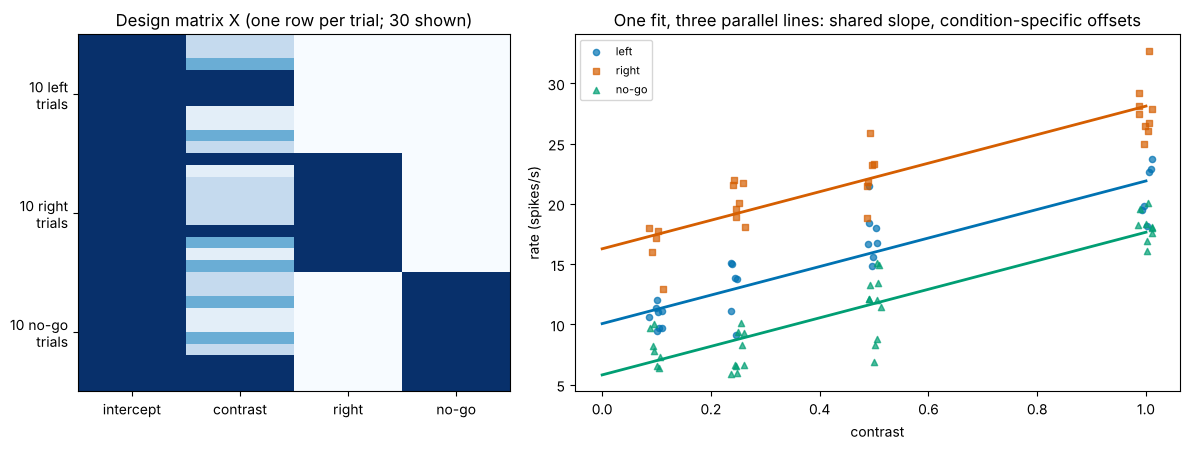

In [19]:
show_rows = np.concatenate([np.flatnonzero(condition == c)[:10] for c in ['left', 'right', 'no-go']])   # 10 trials of each condition
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1, 1.4]})
ax = axes[0]
ax.imshow(X_good[show_rows], aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(['intercept', 'contrast', 'right', 'no-go'])
ax.set_yticks([4.5, 14.5, 24.5]); ax.set_yticklabels(['10 left\ntrials', '10 right\ntrials', '10 no-go\ntrials'])
ax.set_title('Design matrix X (one row per trial; 30 shown)')
ax = axes[1]
c_plot = np.linspace(0, 1, 2)
for (name, ind), colour, mk in zip([('left', is_left), ('right', is_right), ('no-go', is_nogo)], PALETTE, MARKERS):
    m = ind == 1
    ax.scatter(contrast_d[m] + RNG.uniform(-0.015, 0.015, m.sum()), rate_d[m], color=colour, marker=mk, s=20, alpha=0.7, label=name)
    offset = {'left': 0.0, 'right': beta_good[2], 'no-go': beta_good[3]}[name]
    ax.plot(c_plot, beta_good[0] + offset + beta_good[1] * c_plot, color=colour, lw=2)
ax.set_xlabel('contrast'); ax.set_ylabel('rate (spikes/s)')
ax.set_title('One fit, three parallel lines: shared slope, condition-specific offsets')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The fit recovers offsets close to the true +6 (right) and −4 (no-go) spikes/s, and a slope close to 12. Because the model has one contrast column, the three lines are forced to be **parallel**: the model assumes contrast affects all conditions equally. If you suspect otherwise, add **interaction** columns (contrast × is_right, contrast × is_nogo). Every column you add is a hypothesis about the neuron.

# **Part 7: Residuals, R², and Testing on New Data**

### Read the residuals

Least squares always returns *some* answer, even for the wrong model. The **residuals** $\mathbf{r} = \mathbf{y} - \mathbf{X}\hat{\boldsymbol\beta}$ are how you check it. If the model is adequate, the residuals look like structureless noise when plotted against the fitted values or any regressor. A curve or funnel in the residuals means the model is missing something.

**$R^2$** summarises the fit as the fraction of the response's variance that the model explains, $R^2 = 1 - \text{SSE}/\sum_i(y_i - \bar y)^2$. It is 1 for a perfect fit and 0 for a model no better than the mean.

Contrast responses of real visual neurons **saturate**: they rise steeply at low contrast and flatten at high contrast (a Naka–Rushton curve). Fitting a straight line to such data gives a decent-looking $R^2$ and badly patterned residuals.

Straight-line fit: R^2 = 0.76 on the training trials


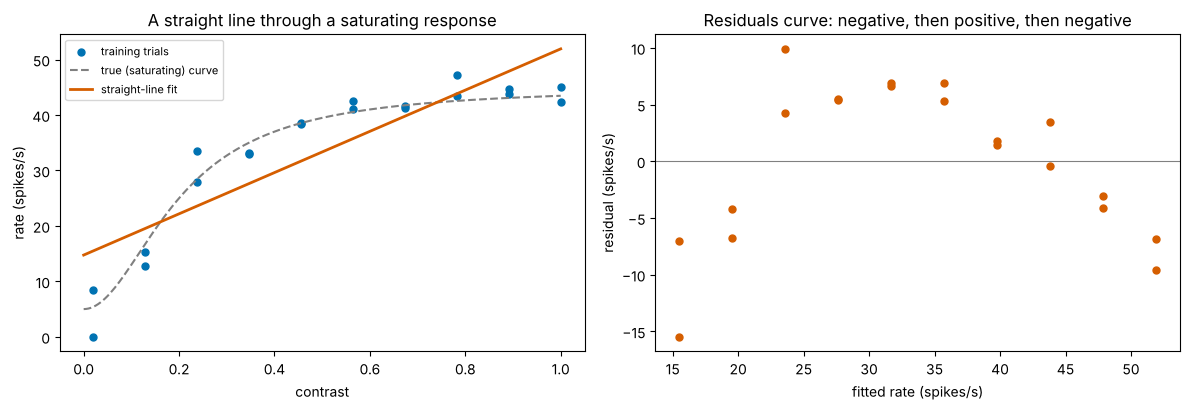

In [20]:
def naka_rushton(c, r_max=40.0, c50=0.2, n=2.0, base=5.0):
    return base + r_max * c**n / (c**n + c50**n)

c_train = np.repeat(np.linspace(0.02, 1.0, 10), 2)                   # 20 training trials
c_test = np.repeat(np.linspace(0.02, 1.0, 25), 4)                     # 100 test trials
y_train = naka_rushton(c_train) + RNG.normal(0, 3.0, c_train.size)
y_test = naka_rushton(c_test) + RNG.normal(0, 3.0, c_test.size)

X1 = np.column_stack([np.ones_like(c_train), c_train])
beta1 = np.linalg.lstsq(X1, y_train, rcond=None)[0]
fitted1 = X1 @ beta1
print(f"Straight-line fit: R^2 = {r_squared(y_train, fitted1):.2f} on the training trials")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
c_fine = np.linspace(0, 1, 200)
axes[0].scatter(c_train, y_train, color=PALETTE[0], s=25, label='training trials')
axes[0].plot(c_fine, naka_rushton(c_fine), color='grey', ls='--', label='true (saturating) curve')
axes[0].plot(c_fine, beta1[0] + beta1[1] * c_fine, color=PALETTE[1], lw=2, label='straight-line fit')
axes[0].set_xlabel('contrast'); axes[0].set_ylabel('rate (spikes/s)'); axes[0].set_title('A straight line through a saturating response'); axes[0].legend(fontsize=8)
axes[1].scatter(fitted1, y_train - fitted1, color=PALETTE[1], s=25)
axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set_xlabel('fitted rate (spikes/s)'); axes[1].set_ylabel('residual (spikes/s)'); axes[1].set_title('Residuals curve: negative, then positive, then negative')
plt.tight_layout()
plt.show()

### Train/test separation: more columns always fit the training data better

Add polynomial columns $c^2, c^3, \dots$ and the training fit can only improve. Each new column gives least squares more freedom, and the extra freedom can always be set to zero. Push far enough and the curve bends to chase the noise in the training trials: an **overfitted** model. (Here the 20 training trials come in pairs at 10 contrasts, so by degree 8 or 9 the curve passes almost through the average of every pair, and training error can fall no further.) The honest measure is the error on **new** data that played no part in the fit. Training error falls as columns are added; test error falls and then rises.

degree : [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
train  : [179.   43.8   8.5   6.4   6.3   5.9   5.2   4.8   3.4   3.4   3.4   3.4
   3.4]
test   : [143.1  39.5  13.2  10.2  10.2   9.9   9.6  10.5  19.4  19.3  20.2  20.2
  20.4]
Lowest test error at degree 6


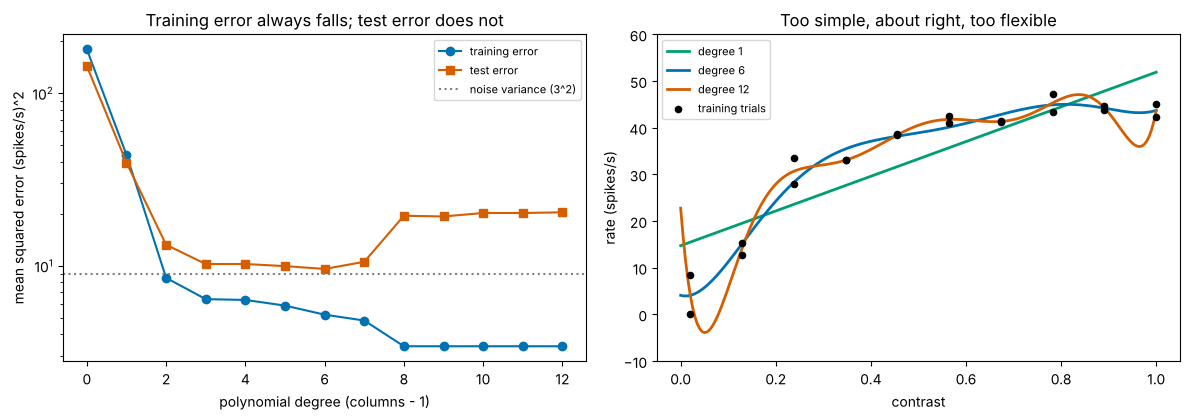

In [21]:
degrees = np.arange(0, 13)
def poly_design(c, d):
    return np.vander(c - 0.5, d + 1, increasing=True)    # centring c helps conditioning (Part 5)
mse_train, mse_test, fits = [], [], []
for d in degrees:
    beta_d = np.linalg.lstsq(poly_design(c_train, d), y_train, rcond=None)[0]
    fits.append(beta_d)
    mse_train.append(np.mean((y_train - poly_design(c_train, d) @ beta_d)**2))
    mse_test.append(np.mean((y_test - poly_design(c_test, d) @ beta_d)**2))
best_d = degrees[int(np.argmin(mse_test))]
print("degree :", degrees)
print("train  :", np.round(mse_train, 1))
print("test   :", np.round(mse_test, 1))
print(f"Lowest test error at degree {best_d}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(degrees, mse_train, 'o-', color=PALETTE[0], label='training error')
axes[0].plot(degrees, mse_test, 's-', color=PALETTE[1], label='test error')
axes[0].axhline(9.0, color='grey', ls=':', label='noise variance (3^2)')
axes[0].set_yscale('log'); axes[0].set_xlabel('polynomial degree (columns - 1)'); axes[0].set_ylabel('mean squared error (spikes/s)^2')
axes[0].set_title('Training error always falls; test error does not'); axes[0].legend(fontsize=8)
for d, colour in [(1, PALETTE[2]), (best_d, PALETTE[0]), (12, PALETTE[1])]:
    axes[1].plot(c_fine, poly_design(c_fine, d) @ fits[d], color=colour, lw=2, label=f'degree {d}')
axes[1].scatter(c_train, y_train, color='black', s=20, zorder=3, label='training trials')
axes[1].set_ylim(-10, 60); axes[1].set_xlabel('contrast'); axes[1].set_ylabel('rate (spikes/s)'); axes[1].set_title('Too simple, about right, too flexible')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Interactive version: drag the degree

In [22]:
fig_deg = make_subplots(rows=1, cols=2, subplot_titles=('Fit to 20 training trials', 'Error vs degree'))
fig_deg.add_trace(go.Scatter(x=c_test, y=y_test, mode='markers', marker=dict(color='lightgrey', size=5), name='test trials'), row=1, col=1)
fig_deg.add_trace(go.Scatter(x=c_train, y=y_train, mode='markers', marker=dict(color='black', size=7), name='training trials'), row=1, col=1)
fig_deg.add_trace(go.Scatter(x=c_fine, y=poly_design(c_fine, 0) @ fits[0], mode='lines', line=dict(color=PALETTE[0], width=3), name='fit'), row=1, col=1)
fig_deg.add_trace(go.Scatter(x=degrees, y=mse_train, mode='lines+markers', line=dict(color=PALETTE[0]), name='train'), row=1, col=2)
fig_deg.add_trace(go.Scatter(x=degrees, y=mse_test, mode='lines+markers', line=dict(color=PALETTE[1]), name='test'), row=1, col=2)
fig_deg.add_trace(go.Scatter(x=[0], y=[mse_test[0]], mode='markers', marker=dict(color='black', size=13, symbol='circle-open', line=dict(width=3)), name='current'), row=1, col=2)
fig_deg.frames = [go.Frame(name=str(d), traces=[2, 5], data=[go.Scatter(x=c_fine, y=np.clip(poly_design(c_fine, d) @ fits[d], -20, 80)), go.Scatter(x=[d], y=[mse_test[d]])],
                           layout=go.Layout(title=f'degree {d}: training MSE {mse_train[d]:.1f}, test MSE {mse_test[d]:.1f} (spikes/s)^2'))
                  for d in degrees]
buttons, sliders = play_pause_and_slider([str(d) for d in degrees], prefix='degree = ', duration=500)
fig_deg.update_yaxes(range=[-10, 60], title_text='rate (spikes/s)', row=1, col=1); fig_deg.update_xaxes(title_text='contrast', row=1, col=1)
fig_deg.update_yaxes(type='log', title_text='MSE', row=1, col=2); fig_deg.update_xaxes(title_text='degree', row=1, col=2)
fig_deg.update_layout(title=fig_deg.frames[0].layout.title.text, template='plotly_white', width=1000, height=480, updatemenus=buttons, sliders=sliders)
fig_deg.show(config=PLOTLY_CONFIG)

**Rules for honest fitting.**
1. Split the data **before** fitting. The test set is touched once, at the end.
2. Every choice that uses data counts as fitting: the polynomial degree, which neurons to include, and the centring and scaling statistics (Lesson 3). Make those choices on the training data only. If several choices are being compared, set aside part of the training data as a **validation** set and choose there.
3. For time series (like the recording below), split by time, not at random: neighbouring time bins are similar, so random splits leak information.

# **Part 8: Mini-Lab — A Least-Squares Decoder for Real Motor Cortex**

Lesson 4 ended with a promise: a decoder fitted directly to data should beat the population vector. Here we fit one.

The data are the motor-cortex recording from Lessons 2 and 4: 171 neurons in a monkey's primary motor cortex during centre-out reaches ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)). This time we decode the full **hand velocity** $(v_x, v_y)$ in every 50 ms bin, not just the direction.

**The model.** For each time bin $t$, $\;\hat{\mathbf{v}}_t = \boldsymbol\beta_0 + \sum_i \boldsymbol\beta_i\,r_{i,t}$: an intercept plus a weighted sum of the neurons' rates. Stacking the bins as rows gives the design matrix $\mathbf{X}$ (one row per bin, an intercept column plus one column per neuron), and the response matrix $\mathbf{Y}$ (one row per bin, columns $v_x$ and $v_y$). Least squares fits both columns of $\mathbf{Y}$ at once: $\hat{\mathbf{B}} = \arg\min\lVert\mathbf{Y} - \mathbf{X}\mathbf{B}\rVert^2$.

**The split.** Fit on the first half of the session, test on the second (Part 7, rule 3).

In [23]:
# Step 1: load, and build the design matrix
import os, urllib.request
from scipy.io import loadmat

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates = m1['spikes'].T.astype(float) / 0.05            # shape (15536, 171): (time bin, neuron), spikes/s  -- note the transpose
vel = m1['handVel'][:2].T * 100                         # shape (15536, 2): (time bin, [vx, vy]), cm/s
n_bins = rates.shape[0]
train = np.arange(n_bins) < n_bins // 2
test = ~train

X_full = np.column_stack([np.ones(n_bins), rates])     # shape (15536, 172): intercept + one column per neuron
print("X_full:", X_full.shape, "  Y:", vel.shape)
print(f"rank of the training design matrix: {np.linalg.matrix_rank(X_full[train])} of {X_full.shape[1]} columns")
print(f"condition number of the training design matrix: {np.linalg.cond(X_full[train]):.1e}")
silent = np.flatnonzero(rates[train].std(axis=0) == 0)
print("neurons that never fire in the training half:", silent, " (total spikes in the whole session:", int(rates[:, silent].sum() * 0.05), ")")

X_full: (15536, 172)   Y: (15536, 2)
rank of the training design matrix: 171 of 172 columns
condition number of the training design matrix: 6.7e+19
neurons that never fire in the training half: [155]  (total spikes in the whole session: 1 )


The design matrix is **rank-deficient**: one neuron never fires in the training half, so its column is all zeros, and its weight could be anything without changing the fit. That is why the condition number is astronomical. `lstsq` would quietly return the minimum-norm answer (weight 0, Part 5), but the cleaner fix is to drop the column. The decision uses only the training data.

In [24]:
# Step 2: drop the silent neuron, fit by least squares, test on the second half
keep = rates[train].std(axis=0) > 0
X = np.column_stack([np.ones(n_bins), rates[:, keep]])            # shape (15536, 171)
print(f"After dropping it: {X.shape[1]} columns, rank {np.linalg.matrix_rank(X[train])}, condition number {np.linalg.cond(X[train]):.1e}")

B_hat = np.linalg.lstsq(X[train], vel[train], rcond=None)[0]       # shape (171, 2): one column of weights per velocity component
pred_test = X[test] @ B_hat
print("Training R^2 (vx, vy):", np.round(r_squared(vel[train], X[train] @ B_hat), 3))
print("Test R^2     (vx, vy):", np.round(r_squared(vel[test], pred_test), 3))

After dropping it: 171 columns, rank 171, condition number 4.7e+03
Training R^2 (vx, vy): [0.53 0.38]
Test R^2     (vx, vy): [0.505 0.313]


### Adding history: the design matrix is where the modelling happens

Motor cortex fires **before** the movement it drives, and one 50 ms bin is noisy. Both suggest giving the decoder the recent past as well. Add columns for each neuron's rate one and two bins earlier (100 ms of history). The design matrix triples in width; nothing else about least squares changes.

In [25]:
def lagged_design(R, n_lags):
    # Row t: [1, rates at t, rates at t-1, ..., rates at t-n_lags+1]. The first n_lags-1 bins are dropped.
    T = R.shape[0]
    blocks = [R[n_lags - 1 - lag: T - lag] for lag in range(n_lags)]
    return np.column_stack([np.ones(T - n_lags + 1)] + blocks)

results = {}
for n_lags in [1, 3, 5]:
    X_lag = lagged_design(rates[:, keep], n_lags)
    Y_lag = vel[n_lags - 1:]
    tr_l, te_l = train[n_lags - 1:], test[n_lags - 1:]
    B_lag = np.linalg.lstsq(X_lag[tr_l], Y_lag[tr_l], rcond=None)[0]
    results[n_lags] = (B_lag, X_lag, Y_lag, tr_l, te_l)
    print(f"{n_lags} bin(s) of history ({X_lag.shape[1]:>3} columns):  train R^2 {np.round(r_squared(Y_lag[tr_l], X_lag[tr_l] @ B_lag), 2)}   "
          f"test R^2 {np.round(r_squared(Y_lag[te_l], X_lag[te_l] @ B_lag), 2)}")

1 bin(s) of history (171 columns):  train R^2 [0.53 0.38]   test R^2 [0.51 0.31]


3 bin(s) of history (511 columns):  train R^2 [0.77 0.68]   test R^2 [0.73 0.56]


5 bin(s) of history (851 columns):  train R^2 [0.84 0.79]   test R^2 [0.79 0.66]


### Least squares against the population vector

Lesson 4 decoded movement **direction** with the population vector. To compare fairly, both decoders use the same information, the last three bins (150 ms) of activity. Both are tested on the same held-out moving bins, and both are scored only on direction.

In [26]:
B3, X3, Y3, tr3, te3 = results[3]
pred3 = X3[te3] @ B3
moving_te = np.linalg.norm(Y3[te3], axis=1) > 10                 # held-out bins with hand speed > 10 cm/s

def angle_error(pred, true):
    d = np.arctan2(pred[:, 1], pred[:, 0]) - np.arctan2(true[:, 1], true[:, 0])
    return np.abs((np.degrees(d) + 180) % 360 - 180)

err_ls = angle_error(pred3[moving_te], Y3[te3][moving_te])

# Population vector from Lesson 4, fitted on the training half
speed = np.linalg.norm(vel, axis=1)
dir_index = np.round((np.degrees(np.arctan2(vel[:, 1], vel[:, 0])) % 360) / 45).astype(int) % 8
theta8 = np.radians(np.arange(0, 360, 45)); D8 = np.vstack([np.cos(theta8), np.sin(theta8)])
tuning = np.stack([rates[train & (speed > 10) & (dir_index == k)].mean(axis=0) for k in range(8)], axis=1)   # (171, 8)
base = tuning.mean(axis=1); cen = tuning - base[:, None]
E_all = cen @ D8.T / 4; model = E_all @ D8
nrm = np.linalg.norm(cen, axis=1) * np.linalg.norm(model, axis=1)
tuned = np.where(nrm > 0, (cen * model).sum(axis=1) / np.where(nrm > 0, nrm, 1), 0) > 0.8
g = np.linalg.norm(E_all[tuned], axis=1); U = E_all[tuned] / g[:, None]
D_pv = (2 / tuned.sum()) * (U / g[:, None]).T
avg3 = (rates[2:] + rates[1:-1] + rates[:-2]) / 3                 # causal 3-bin average, aligned with X3's rows
pv_out = (avg3[te3][moving_te][:, tuned] - base[tuned]) @ D_pv.T
err_pv = angle_error(pv_out, Y3[te3][moving_te])

print(f"Held-out moving bins: {moving_te.sum()}")
print(f"Median direction error: population vector ({tuned.sum()} tuned neurons) {np.median(err_pv):.1f} deg;  least squares (all neurons) {np.median(err_ls):.1f} deg")

Held-out moving bins: 1194
Median direction error: population vector (82 tuned neurons) 21.1 deg;  least squares (all neurons) 11.0 deg


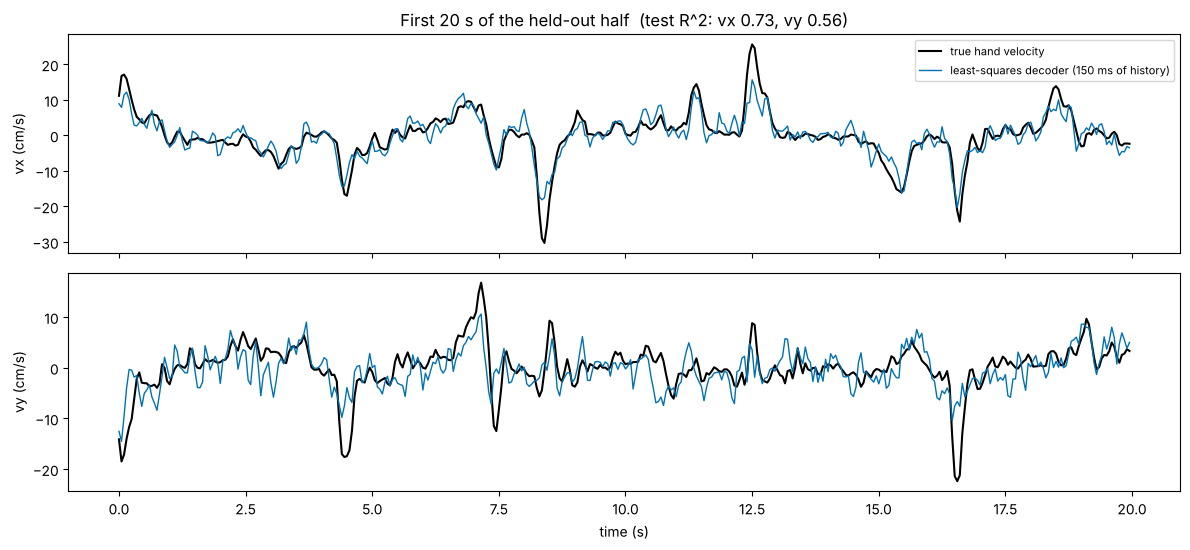

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
t_axis = np.arange(400) * 0.05
for ax, k, name in zip(axes, [0, 1], ['vx', 'vy']):
    ax.plot(t_axis, Y3[te3][:400, k], color='black', lw=1.5, label='true hand velocity')
    ax.plot(t_axis, pred3[:400, k], color=PALETTE[0], lw=1, label='least-squares decoder (150 ms of history)')
    ax.set_ylabel(f'{name} (cm/s)')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].set_title(f'First 20 s of the held-out half  (test R^2: vx {r_squared(Y3[te3], pred3)[0]:.2f}, vy {r_squared(Y3[te3], pred3)[1]:.2f})')
axes[1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

#### Interactive version: zoom into the decoded velocity

In [28]:
fig_vel = make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=('vx (cm/s)', 'vy (cm/s)'))
t_long = np.arange(2000) * 0.05
for row, k in [(1, 0), (2, 1)]:
    fig_vel.add_trace(go.Scatter(x=t_long, y=Y3[te3][:2000, k], mode='lines', line=dict(color='black', width=1.5), name='true', showlegend=row == 1), row=row, col=1)
    fig_vel.add_trace(go.Scatter(x=t_long, y=pred3[:2000, k], mode='lines', line=dict(color=PALETTE[0], width=1), name='decoded', showlegend=row == 1), row=row, col=1)
fig_vel.update_xaxes(title_text='time in held-out half (s)', row=2, col=1)
fig_vel.update_layout(title='Least-squares decoding of hand velocity (drag to zoom)', template='plotly_white', width=1000, height=560)
fig_vel.show(config=PLOTLY_CONFIG)

**Interpretation.** A decoder fitted by least squares, using every neuron and 150 ms of history, reconstructs hand velocity on held-out data with $R^2$ around 0.7 for $v_x$ and 0.55 for $v_y$. It roughly halves the population vector's direction error on the same bins. The population vector assumed cosine tuning and used only the 82 well-tuned neurons. Least squares makes no assumption about tuning: it lets the data weight every neuron, and every past bin, by how much it helps. The design matrix carried the modelling choices: an intercept, which neurons to include (the silent one dropped), and how much history.

**Limitations.** The gap between training and test $R^2$ grows with the number of columns: with 5 bins of history the decoder has 851 weights. Exercise 7 shows what happens when there are more weights than training samples. Neighbouring 50 ms bins are not independent observations, so the fit is less certain than the sample size suggests. A linear decoder cannot capture nonlinear tuning or dynamics; real brain–computer interfaces add **regularisation** (Lesson 15) and models of how velocity evolves. And decoding well does not show how the brain uses this activity.

# **Part 9: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Solve $\mathbf{A}\mathbf{x} = \mathbf{b}$ | estimating unknown synaptic weights or connection strengths from controlled stimulation | solving for parameters in closed form |
| Least squares, $\mathbf{X}\boldsymbol\beta \approx \mathbf{y}$ | encoding models (stimulus → rate), decoders (rates → behaviour), the general linear model (GLM) of fMRI analysis | linear regression; the readout layer of reservoir and kernel models |
| Design matrix, indicators | task regressors and condition coding in fMRI and electrophysiology | feature engineering, one-hot encoding |
| History columns | temporal filters; lagged regressors in BCI decoders | autoregressive features for time series |
| Residual analysis | checking a tuning or GLM model before interpreting coefficients | diagnosing model misspecification |
| Train / test split | cross-validated decoding accuracy | validation sets, early stopping, model selection |
| Conditioning, pseudoinverse | correlated regressors (collinearity) make coefficients unreliable | why solvers use QR/SVD; regularisation (Lesson 15) |

In fMRI, the **general linear model** fits every voxel's time series with the same design matrix: columns for each task condition (convolved with a haemodynamic response), plus nuisance columns for head motion and drift. Least squares, voxel by voxel, gives the activation maps reported in thousands of papers.

# **Part 10: Summary and Lesson 6 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Linear system | $\mathbf{A}\mathbf{x} = \mathbf{b}$ | rows: intersecting lines/planes; columns: combine to reach $\mathbf{b}$ |
| Solvability | rank $[\mathbf{A}\mid\mathbf{b}]$ = rank $\mathbf{A}$ | unique if also rank = number of unknowns |
| Elimination | row operations, back substitution | `np.linalg.solve`; avoid `inv` |
| Condition number | $\kappa(\mathbf{A})$, `np.linalg.cond` | up to $\log_{10}\kappa$ digits lost |
| Overdetermined | tall $\mathbf{A}$, $\mathbf{b}$ off the column space | no exact solution: use least squares |
| Underdetermined | wide $\mathbf{A}$, null directions | infinitely many solutions; pinv picks the shortest |
| Least squares | $\min\lVert\mathbf{b} - \mathbf{A}\mathbf{x}\rVert^2$ | projection of $\mathbf{b}$; residual $\perp$ columns |
| Normal equations | $\mathbf{A}^{\mathsf T}\mathbf{A}\hat{\mathbf{x}} = \mathbf{A}^{\mathsf T}\mathbf{b}$ | right on paper; squares $\kappa$ on a computer |
| Solver | `np.linalg.lstsq` | use this |
| Design matrix | intercept, units, indicators (one fewer than categories) | every column is a hypothesis |
| Model checking | residual plots, $R^2$ | patterned residuals mean a missing ingredient |
| Honest evaluation | train / test (validation) split | training error always flatters |

**Lesson 6** asks what happens when a matrix is applied **over and over**, as in a recurrent network where today's activity is $\mathbf{W}$ times yesterday's. Some directions are only stretched, never turned. Those **eigenvectors**, and their stretch factors the **eigenvalues**, decide whether activity dies away, explodes or persists. They are also the hidden machinery behind the condition number and the pseudoinverse used here.